In [1]:
import subprocess, sys
def _pip(*pkgs):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=False)
# Colab already ships sklearn/pandas/matplotlib; add the extras we need.
_pip("lightgbm", "shap", "xarray", "netcdf4", "global-land-mask")
print("Dependencies ready.")

Dependencies ready.


In [2]:
import os, gc, json, math, time, random, warnings
from dataclasses import dataclass, field
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
warnings.filterwarnings("ignore")

import lightgbm as lgb
from scipy.stats import genpareto
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             brier_score_loss, f1_score, mean_absolute_error)
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

SEED = 42
random.seed(SEED); np.random.seed(SEED)

mpl.rcParams.update({
    "figure.dpi": 120, "font.family": "serif", "font.size": 11,
    "axes.titlesize": 12.5, "axes.labelsize": 11,
    "axes.spines.top": False, "axes.spines.right": False, "figure.autolayout": False,
})
print("LightGBM", lgb.__version__, "| NumPy", np.__version__, "| Pandas", pd.__version__)

LightGBM 4.6.0 | NumPy 2.1.3 | Pandas 2.2.3


In [3]:
# Optional Google Drive mount (Colab). Safe no-op elsewhere.
BASE = Path(".")
try:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = Path("/content/drive/MyDrive/MSc Dissertation")
    BASE.mkdir(parents=True, exist_ok=True)
except Exception:
    print("Not on Colab (or Drive not mounted) - using local working directory.")
print("BASE =", BASE.resolve())

Mounted at /content/drive
BASE = /content/drive/MyDrive/MSc Dissertation


In [4]:
@dataclass
class Config:
    # run control
    RUN_MODE: str = "auto"
    # ERA5 domain
    AREA: tuple = (56.0, -6.0, 50.0, 2.0)   # N, W, S, E
    GRID: float = 0.25
    YEARS: tuple = tuple(range(2015, 2027))
    # paths
    RAW_DIR: Path = field(default_factory=lambda: BASE / "era5_england_raw_full")
    # processing knobs
    TIME_STRIDE: int = 1             # 1 = hourly; 3 => 3-hourly (cuts RAM 3x)
    MAX_CELLS: int = 0               # 0 = all land/coastal cells; else cap
    LAND_ONLY: bool = True
    # extreme-event definition
    POT_Q: float = 0.98
    DECLUS_HRS: int = 24
    # forecasting task
    HIST: int = 48                   # history window for rolling aggregates
    LEAD: int = 24                   # exceedance anywhere in (t, t+LEAD]
    SAMPLE_STRIDE: int = 3
    # chronological split
    TRAIN_FRAC: float = 0.70
    VAL_FRAC: float = 0.15
    # LightGBM occurrence model
    N_EST: int = 6000
    LR: float = 0.02
    NUM_LEAVES: int = 31
    MIN_CHILD: int = 500
    FEAT_FRAC: float = 0.8
    BAG_FRAC: float = 0.8
    EARLY: int = 300
    # physics constraints
    USE_MONOTONE: bool = True        # monotone physical priors on the tree shape
    RUN_ADV_ABLATION: bool = True    # measure the contribution of the advective term
    TRAIN_CAP: int = 6_000_000       # max training rows fed to LightGBM
    VAL_CAP: int = 1_500_000
    # magnitude model
    QUANTILES: tuple = (0.1, 0.25, 0.5, 0.75, 0.9)

CFG = Config()
CFG.RAW_DIR.mkdir(parents=True, exist_ok=True)
QLEVELS = np.array(CFG.QUANTILES, dtype=np.float32)
MEDIAN_IDX = int(np.where(QLEVELS == 0.5)[0][0])
print("Config ready. RUN_MODE =", CFG.RUN_MODE)
print("RAW_DIR =", CFG.RAW_DIR)
print("Tip: on a low-RAM runtime set CFG.TIME_STRIDE=3 and CFG.MAX_CELLS=250 before running on.")

Config ready. RUN_MODE = auto
RAW_DIR = /content/drive/MyDrive/MSc Dissertation/era5_england_raw_full
Tip: on a low-RAM runtime set CFG.TIME_STRIDE=3 and CFG.MAX_CELLS=250 before running on.


In [5]:
# canonical short-name mapping & robust ERA5 loader
RENAME = {
    "u10": "u10", "v10": "v10", "u100": "u100", "v100": "v100",
    "i10fg": "i10fg", "fg10": "fg10", "cape": "cape",
    "kx": "kx", "tcwv": "tcwv", "blh": "blh", "msl": "msl", "sp": "sp",
    "t2m": "t2m", "d2m": "d2m",
    "10fg": "fg10", "instantaneous_10m_wind_gust": "i10fg",
}

def load_era5_netcdf(files, cfg):
    import xarray as xr
    ds = xr.open_mfdataset([str(f) for f in files], combine="by_coords",
                           engine="netcdf4", chunks={"time": 1500})
    for a, b in [("latitude", "lat"), ("longitude", "lon"), ("valid_time", "time")]:
        if a in ds.dims or a in ds.coords:
            ds = ds.rename({a: b})
    if "expver" in ds.dims:
        ds = ds.mean("expver")
    elif "expver" in ds.coords:
        ds = ds.drop_vars("expver")
    ds = ds.rename({k: v for k, v in RENAME.items() if k in ds.variables})
    if cfg.TIME_STRIDE > 1:
        ds = ds.isel(time=slice(None, None, cfg.TIME_STRIDE))
    ds = ds.sortby("time").sortby("lat").sortby("lon")
    times = pd.DatetimeIndex(ds.time.values)
    lats = ds.lat.values.astype(np.float32)
    lons = ds.lon.values.astype(np.float32)
    fields = {}
    for name in ["u10","v10","u100","v100","i10fg","fg10","cape","kx",
                 "tcwv","blh","msl","sp","t2m","d2m"]:
        if name in ds.variables:
            fields[name] = ds[name].transpose("time","lat","lon").values.astype(np.float32)
    if "sp"  in fields: fields["sp"]  = fields["sp"] / 100.0   # Pa -> hPa
    if "msl" in fields: fields["msl"] = fields["msl"] / 100.0  # Pa -> hPa
    for k in ("t2m", "d2m"):
        if k in fields: fields[k] = fields[k] - 273.15         # K -> degC
    ds.close()
    return times, lats, lons, fields

RAW_FILES = sorted(CFG.RAW_DIR.glob("*.nc"))
print(f"NetCDF files found in {CFG.RAW_DIR}: {len(RAW_FILES)}")

NetCDF files found in /content/drive/MyDrive/MSc Dissertation/era5_england_raw_full: 276


In [7]:
# load ERA5
if not RAW_FILES:
    raise FileNotFoundError(f"no ERA5 NetCDF files found in {CFG.RAW_DIR}")
times, lats, lons, FIELDS = load_era5_netcdf(RAW_FILES, CFG)

nlat, nlon = len(lats), len(lons)
T = len(times)
print("ERA5 data loaded")
print(f"  time : {times[0]} -> {times[-1]}  ({T:,} steps, stride={CFG.TIME_STRIDE}h)")
print(f"  grid : {nlat} lat x {nlon} lon = {nlat*nlon} cells  |  vars: {sorted(FIELDS)}")

ERA5 data loaded
  time : 2015-01-01 00:00:00 -> 2026-06-30 19:00:00  (100,772 steps, stride=1h)
  grid : 25 lat x 33 lon = 825 cells  |  vars: ['blh', 'cape', 'd2m', 'fg10', 'i10fg', 'kx', 'msl', 'sp', 't2m', 'tcwv', 'u10', 'u100', 'v10', 'v100']


In [8]:
# derived scalar fields + land mask + cell selection
def hypot(a, b): return np.sqrt(a*a + b*b)

FIELDS["ws10"]  = hypot(FIELDS["u10"],  FIELDS["v10"]).astype(np.float32)
FIELDS["ws100"] = hypot(FIELDS["u100"], FIELDS["v100"]).astype(np.float32)
if "i10fg" in FIELDS:
    FIELDS["gust"] = FIELDS["i10fg"]
elif "fg10" in FIELDS:
    FIELDS["gust"] = FIELDS["fg10"]
else:
    FIELDS["gust"] = (1.4*FIELDS["ws10"]).astype(np.float32)

def _clean_field(a):
    if not np.isnan(a).any():
        return a.astype(np.float32)
    Tt = a.shape[0]
    flat = pd.DataFrame(a.reshape(Tt, -1)).interpolate(limit_direction="both", axis=0)
    flat = flat.fillna(flat.mean())
    return flat.values.reshape(a.shape).astype(np.float32)

_nan_before = sum(int(np.isnan(v).sum()) for v in FIELDS.values())
if _nan_before:
    FIELDS = {k: _clean_field(v) for k, v in FIELDS.items()}
    print(f"NaN cleaning: {_nan_before:,} missing values filled")

land_mask = np.ones((nlat, nlon), dtype=bool)
if CFG.LAND_ONLY:
    try:
        from global_land_mask import globe
        from scipy.ndimage import binary_dilation
        LO, LA = np.meshgrid(lons, lats)
        land_mask = binary_dilation(globe.is_land(LA, LO), iterations=1)
        print(f"Land+coastal cells: {land_mask.sum()}/{land_mask.size}")
    except Exception as e:
        print("global_land_mask unavailable - keeping all cells:", e)

cell_ii, cell_jj = np.where(land_mask)
if CFG.MAX_CELLS and len(cell_ii) > CFG.MAX_CELLS:
    sel = np.linspace(0, len(cell_ii)-1, CFG.MAX_CELLS).astype(int)
    cell_ii, cell_jj = cell_ii[sel], cell_jj[sel]
N_CELLS = len(cell_ii)
cell_lat = lats[cell_ii].astype(np.float32)
cell_lon = lons[cell_jj].astype(np.float32)

def cs(name):
    """Cell-stack a full-grid field -> (T, N_CELLS)."""
    return FIELDS[name][:, cell_ii, cell_jj].astype(np.float32)

gust_cells = cs("gust")                                # (T, N_CELLS) - used everywhere below
print(f"Modelling {N_CELLS} cells | gust mean={gust_cells.mean():.2f}  max={gust_cells.max():.2f} m/s")

NaN cleaning: 1,849,650 missing values filled
Land+coastal cells: 520/825
Modelling 520 cells | gust mean=8.71  max=44.62 m/s


In [13]:
# per-cell P98 over the full record, for the descriptive statistics below
thr_cell_all = np.percentile(gust_cells, CFG.POT_Q*100, axis=0)

def cell_events(x, thr, gap):
    """Declustered exceedance peak indices for a 1-D series (runs declustering)."""
    ex = x > thr
    if not ex.any():
        return np.empty(0, dtype=int)
    d = np.diff(ex.astype(np.int8))
    starts = np.flatnonzero(d == 1) + 1
    ends   = np.flatnonzero(d == -1) + 1
    if ex[0]:  starts = np.r_[0, starts]
    if ex[-1]: ends   = np.r_[ends, len(x)]
    peaks = np.array([s + int(np.argmax(x[s:e])) for s, e in zip(starts, ends)])
    sel = [peaks[0]]
    for p in peaks[1:]:
        if p - sel[-1] >= gap:
            sel.append(p)
        elif x[p] > x[sel[-1]]:
            sel[-1] = p
    return np.asarray(sel)

# per-cell ADI / CV2 at local P98 (full record - descriptive)
adi = np.full(N_CELLS, np.nan, np.float32)
cv2 = np.full(N_CELLS, np.nan, np.float32)
n_ev = np.zeros(N_CELLS, np.int32)
ia_pool = []
for k in range(N_CELLS):
    pk = cell_events(gust_cells[:, k], thr_cell_all[k], CFG.DECLUS_HRS)
    n_ev[k] = len(pk)
    if len(pk) >= 3:
        ia = np.diff(pk).astype(np.float32) * CFG.TIME_STRIDE
        exc = gust_cells[pk, k] - thr_cell_all[k]
        adi[k] = ia.mean()
        cv2[k] = (exc.std() / max(exc.mean(), 1e-6))**2
        ia_pool.append(ia)
ia_pool = np.concatenate(ia_pool) if ia_pool else np.array([])
print(f"Events per cell: median {np.median(n_ev):.0f}  [{n_ev.min()} - {n_ev.max()}]")
print(f"ADI  : median {np.nanmedian(adi):.0f} h  | CV2: median {np.nanmedian(cv2):.2f}")

Events per cell: median 260  [213 - 301]
ADI  : median 385 h  | CV2: median 0.76


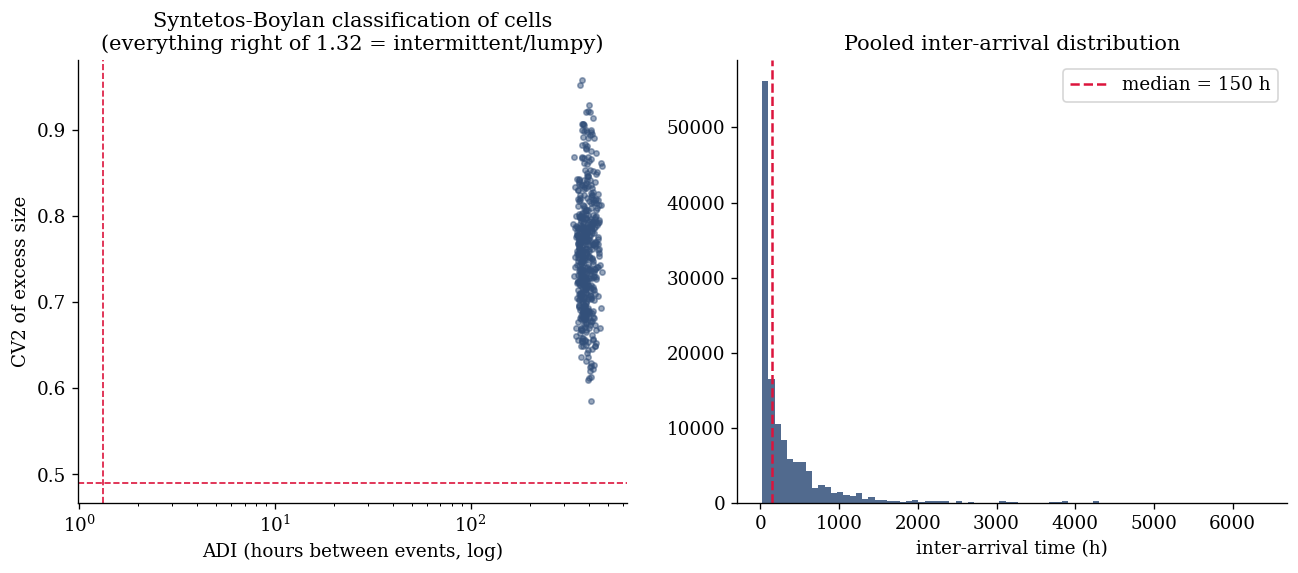

Share of cells classified 'lumpy' (hard for classical forecasting): 100%


In [14]:
# Syntetos-Boylan classification + inter-arrival distribution
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
ok = ~np.isnan(adi)
ax[0].scatter(adi[ok], cv2[ok], s=10, alpha=0.5, c="#33507a")
ax[0].axvline(1.32, color="crimson", ls="--", lw=1)
ax[0].axhline(0.49, color="crimson", ls="--", lw=1)
ax[0].set_xscale("log")
ax[0].set_xlabel("ADI (hours between events, log)"); ax[0].set_ylabel("CV2 of excess size")
ax[0].set_title("Syntetos-Boylan classification of cells\n(everything right of 1.32 = intermittent/lumpy)")
if len(ia_pool):
    ax[1].hist(ia_pool, bins=80, color="#33507a", alpha=0.85)
    ax[1].axvline(np.median(ia_pool), color="crimson", ls="--",
                  label=f"median = {np.median(ia_pool):.0f} h")
    ax[1].set_xlabel("inter-arrival time (h)"); ax[1].set_title("Pooled inter-arrival distribution")
    ax[1].legend()
plt.show()
lumpy = float(((adi[ok] > 1.32) & (cv2[ok] > 0.49)).mean())
print(f"Share of cells classified 'lumpy' (hard for classical forecasting): {lumpy*100:.0f}%")

GPD fit on 30,955 pooled excesses: shape xi=-0.140, scale sigma=3.619


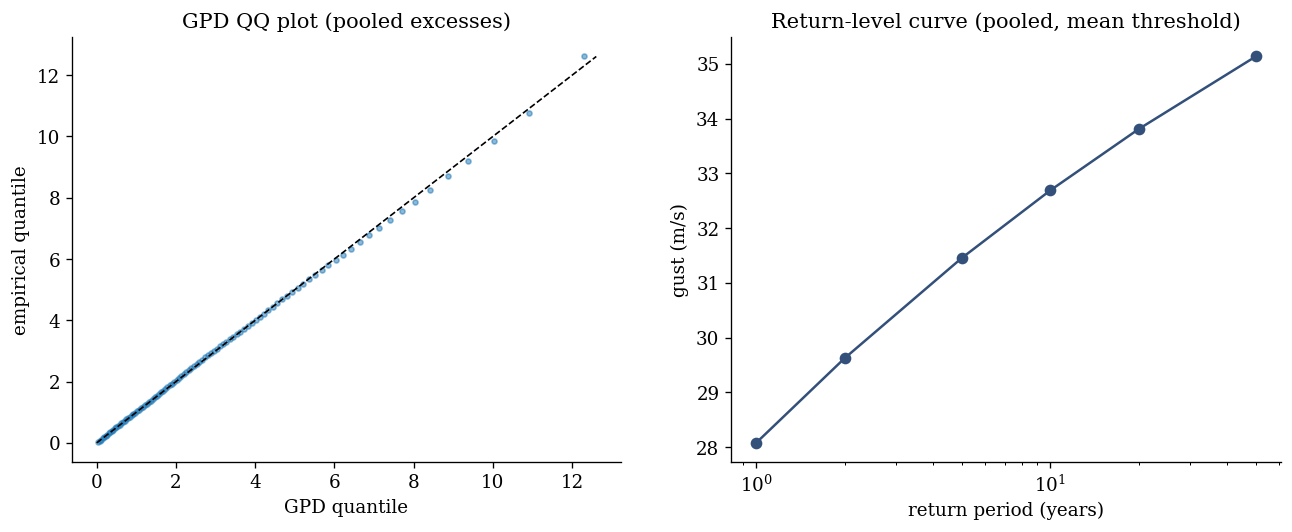

Return levels (m/s above threshold): {1: 9.13, 2: 10.68, 5: 12.51, 10: 13.74, 20: 14.86, 50: 16.19}


In [15]:
# pooled GPD fit on declustered excesses (subset of cells for speed)
rng = np.random.default_rng(SEED)
k_sub = rng.choice(N_CELLS, size=min(N_CELLS, 120), replace=False)
exc_pool = []
for k in k_sub:
    pk = cell_events(gust_cells[:, k], thr_cell_all[k], CFG.DECLUS_HRS)
    if len(pk):
        exc_pool.append(gust_cells[pk, k] - thr_cell_all[k])
exc_pool = np.concatenate(exc_pool)
exc_pool = exc_pool[exc_pool > 0]

xi, loc, sigma = genpareto.fit(exc_pool, floc=0)
print(f"GPD fit on {len(exc_pool):,} pooled excesses: shape xi={xi:.3f}, scale sigma={sigma:.3f}")

years_span = (times[-1] - times[0]).days / 365.25
lam = len(exc_pool) / len(k_sub) / years_span          # events / cell / year
Tr = np.array([1, 2, 5, 10, 20, 50], float)
rl = genpareto.ppf(1 - 1/(lam*Tr), xi, 0, sigma)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
th_q = np.linspace(0.01, 0.99, 99)
emp = np.quantile(exc_pool, th_q)
mod = genpareto.ppf(th_q, xi, 0, sigma)
ax[0].plot(mod, emp, "o", ms=3, alpha=0.5); lim = [0, max(emp.max(), mod.max())]
ax[0].plot(lim, lim, "k--", lw=1)
ax[0].set_xlabel("GPD quantile"); ax[0].set_ylabel("empirical quantile")
ax[0].set_title("GPD QQ plot (pooled excesses)")
ax[1].plot(Tr, rl + thr_cell_all[k_sub].mean(), "o-", color="#33507a")
ax[1].set_xscale("log"); ax[1].set_xlabel("return period (years)")
ax[1].set_ylabel("gust (m/s)"); ax[1].set_title("Return-level curve (pooled, mean threshold)")
plt.show()
GPD_PARAMS = dict(xi=float(xi), sigma=float(sigma), lam=float(lam))
print("Return levels (m/s above threshold):",
      {int(t): round(float(r), 2) for t, r in zip(Tr, rl)})

In [16]:
# chronological split boundaries
tstamp = times.values.astype("datetime64[ns]")
span = tstamp[-1] - tstamp[0]
train_end = tstamp[0] + span * CFG.TRAIN_FRAC
val_end   = tstamp[0] + span * (CFG.TRAIN_FRAC + CFG.VAL_FRAC)
is_train_t = tstamp <= train_end
print(f"Split: train <= {str(train_end)[:10]} | val <= {str(val_end)[:10]} | test after")

# per-cell TRAIN P98 threshold - used for target AND intermittency state features
thr_train = np.array([np.nanpercentile(gust_cells[is_train_t, k], CFG.POT_Q*100)
                      for k in range(N_CELLS)], dtype=np.float32)
print(f"Train P{int(CFG.POT_Q*100)} threshold: mean={thr_train.mean():.2f} m/s "
      f"[{thr_train.min():.1f}, {thr_train.max():.1f}]")

Split: train <= 2023-01-18 | val <= 2024-10-08 | test after
Train P98 threshold: mean=19.08 m/s [16.8, 23.9]


In [18]:
# grid-level synoptic features from MSLP
GRID_KM = CFG.GRID * 111.32
lat_rad = np.deg2rad(lats)
dlat_km = GRID_KM
dlon_km = np.maximum(GRID_KM*np.cos(lat_rad), 1e-3)

msl_g = FIELDS["msl"]
gy = np.gradient(msl_g, axis=1) / dlat_km
gx = np.gradient(msl_g, axis=2) / dlon_km[None, :, None]
pgf_g = np.sqrt(gx*gx + gy*gy).astype(np.float32)
lap_g = (np.gradient(gy, axis=1) + np.gradient(gx, axis=2)).astype(np.float32)
f_cor = np.maximum(2*7.292e-5*np.abs(np.sin(lat_rad)), 2e-5)[None, :, None]
vgeo_g = (pgf_g*100.0/1000.0 / (1.225*f_cor)).astype(np.float32)
msl_tend_g = np.zeros_like(msl_g); msl_tend_g[3:] = msl_g[3:] - msl_g[:-3]
print("Synoptic grid features computed:", pgf_g.shape)

Synoptic grid features computed: (100772, 25, 33)


In [19]:
# base per-cell features: kinematic / convective / synoptic
eps = 1e-6
FEAT = {}                                   # name -> (T, N_CELLS)

ws10c, ws100c = cs("ws10"), cs("ws100")
shear = (ws100c - ws10c).astype(np.float32)
u10c, v10c = cs("u10"), cs("v10")
wdir = np.arctan2(v10c, u10c)
FEAT["ws10"] = ws10c; FEAT["ws100"] = ws100c; FEAT["gust"] = gust_cells
FEAT["gust_factor"] = (gust_cells/(ws10c + eps)).astype(np.float32)
FEAT["shear"] = shear
FEAT["wdir_sin"] = np.sin(wdir).astype(np.float32)
FEAT["wdir_cos"] = np.cos(wdir).astype(np.float32)
FEAT["blh"] = cs("blh"); FEAT["t2m"] = cs("t2m")

cape = cs("cape") if "cape" in FIELDS else np.zeros_like(ws10c)
FEAT["cape"] = cape
FEAT["sqrt_cape"] = np.sqrt(np.clip(cape, 0, None)).astype(np.float32)
FEAT["wmaxshear"] = (np.sqrt(2*np.clip(cape, 0, None))*shear).astype(np.float32)
for nm in ["kx", "tcwv"]:
    FEAT[nm] = cs(nm) if nm in FIELDS else np.zeros_like(ws10c)
FEAT["dd"] = (cs("t2m") - cs("d2m")).astype(np.float32) if "d2m" in FIELDS else np.zeros_like(ws10c)

FEAT["msl"] = msl_g[:, cell_ii, cell_jj].astype(np.float32)
FEAT["pgf"] = pgf_g[:, cell_ii, cell_jj].astype(np.float32)
FEAT["lap"] = lap_g[:, cell_ii, cell_jj].astype(np.float32)
FEAT["vgeo"] = vgeo_g[:, cell_ii, cell_jj].astype(np.float32)
FEAT["msl_tend"] = msl_tend_g[:, cell_ii, cell_jj].astype(np.float32)

del u10c, v10c, wdir
gc.collect()
print(f"Base features: {len(FEAT)}")

Base features: 20


In [20]:
# spatial neighbourhood features (5x5 window ~ 125 km of context)
# Neighbourhood max/mean catch storms that have reached adjacent cells but not this one
# yet; the advection term -(V . grad gust) is the physical 'upwind gust incoming' signal.
from scipy.ndimage import maximum_filter, uniform_filter

def nmax(a):  return maximum_filter(a, size=(1, 5, 5), mode="nearest")
def nmean(a): return uniform_filter(a, size=(1, 5, 5), mode="nearest")

gust_g = FIELDS["gust"]
cape_g = FIELDS["cape"] if "cape" in FIELDS else np.zeros_like(gust_g)
wmax_g = (np.sqrt(2*np.clip(cape_g, 0, None))
          * (FIELDS["ws100"] - FIELDS["ws10"])).astype(np.float32)

FEAT["gust_nmax5"]      = nmax(gust_g)[:, cell_ii, cell_jj].astype(np.float32)
FEAT["cape_nmean5"]     = nmean(cape_g)[:, cell_ii, cell_jj].astype(np.float32)
FEAT["wmaxshear_nmax5"] = nmax(wmax_g)[:, cell_ii, cell_jj].astype(np.float32)
FEAT["pgf_nmax5"]       = nmax(pgf_g)[:, cell_ii, cell_jj].astype(np.float32)

# advection proxy: (m/s)/h of gust change advected by the 10 m wind (u in km/h x grad per km)
ggy = np.gradient(gust_g, axis=1) / dlat_km
ggx = np.gradient(gust_g, axis=2) / dlon_km[None, :, None]
adv = -(3.6*FIELDS["u10"]*ggx + 3.6*FIELDS["v10"]*ggy)
FEAT["adv_gust"] = adv[:, cell_ii, cell_jj].astype(np.float32)

del wmax_g, ggx, ggy, adv, gy, gx, pgf_g, lap_g, vgeo_g, msl_tend_g
gc.collect()
print("Spatial neighbourhood features added:",
      [c for c in FEAT if "nmax5" in c or "nmean5" in c or c == "adv_gust"])

Spatial neighbourhood features added: ['gust_nmax5', 'cape_nmean5', 'wmaxshear_nmax5', 'pgf_nmax5', 'adv_gust']


In [21]:
# intermittency features (the intermittent-demand logic, as predictors)
exc_state = gust_cells > thr_train[None, :]              # causal state w.r.t. train threshold

# time since last exceedance + previous inter-arrival (strictly before t)
tsl = np.zeros((T, N_CELLS), np.float32)
prev_ia = np.zeros((T, N_CELLS), np.float32)
last = np.full(N_CELLS, -10**6, np.int64)
last2 = np.full(N_CELLS, -2*10**6, np.int64)
tt = np.arange(T, dtype=np.int64)
for t in range(T):
    tsl[t] = tt[t] - last
    prev_ia[t] = last - last2
    hit = exc_state[t]
    last2 = np.where(hit, last, last2)
    last = np.where(hit, t, last)
CLIP_H = 24*30
tsl = np.clip(tsl, 0, CLIP_H).astype(np.float32)
prev_ia = np.clip(prev_ia, 0, CLIP_H).astype(np.float32)
FEAT["tsl"] = tsl
FEAT["prev_ia"] = prev_ia

# causal rolling exceedance counts (7-day and 30-day)
csum = np.cumsum(exc_state.astype(np.float32), axis=0)
for nm, win_d in [("roll7", 7), ("roll30", 30)]:
    w = 24*win_d
    r = np.zeros_like(csum)
    r[w:] = csum[w:] - csum[:-w]; r[:w] = csum[:w]
    FEAT[nm] = r.astype(np.float32)
del csum; gc.collect()

# static per-cell intermittency stats from TRAIN period only (leakage-free)
SFEAT = {}
adi_tr = np.full(N_CELLS, np.nan, np.float32)
cv2_tr = np.full(N_CELLS, np.nan, np.float32)
evrate_tr = np.zeros(N_CELLS, np.float32)
tr_years = is_train_t.sum() * CFG.TIME_STRIDE / (24*365.25)
for k in range(N_CELLS):
    pk = cell_events(gust_cells[is_train_t, k], thr_train[k], CFG.DECLUS_HRS)
    evrate_tr[k] = len(pk) / max(tr_years, 1e-6)
    if len(pk) >= 3:
        ia = np.diff(pk).astype(np.float32) * CFG.TIME_STRIDE
        ex = gust_cells[is_train_t, k][pk] - thr_train[k]
        adi_tr[k] = ia.mean()
        cv2_tr[k] = (ex.std()/max(ex.mean(), 1e-6))**2
adi_tr = np.nan_to_num(adi_tr, nan=float(np.nanmedian(adi_tr)))
cv2_tr = np.nan_to_num(cv2_tr, nan=float(np.nanmedian(cv2_tr)))
SFEAT["adi_cell"] = adi_tr
SFEAT["cv2_cell"] = cv2_tr
SFEAT["evrate_cell"] = evrate_tr
SFEAT["thr_cell"] = thr_train
SFEAT["lat_cell"] = cell_lat
SFEAT["lon_cell"] = cell_lon
print(f"Intermittency features ready. Train event rate: {evrate_tr.mean():.1f} events/cell/year")

Intermittency features ready. Train event rate: 22.6 events/cell/year


In [22]:
# temporal aggregates over the history window (replaces the transformer encoder)
AGG_KEYS = ["gust", "ws100", "shear", "cape", "wmaxshear", "pgf", "vgeo"]

def roll_max(a, w):
    return pd.DataFrame(a).rolling(w, min_periods=1).max().values.astype(np.float32)

def roll_mean(a, w):
    c = np.cumsum(a, axis=0, dtype=np.float64)
    out = np.empty_like(a, dtype=np.float32)
    out[:w] = (c[:w] / np.arange(1, w+1)[:, None]).astype(np.float32)
    out[w:] = ((c[w:] - c[:-w]) / w).astype(np.float32)
    return out

for key in AGG_KEYS:
    a = FEAT[key]
    FEAT[f"{key}_max24"]  = roll_max(a, 24)
    FEAT[f"{key}_max48"]  = roll_max(a, CFG.HIST)
    FEAT[f"{key}_mean24"] = roll_mean(a, 24)

def tend(a, k):
    o = np.zeros_like(a); o[k:] = a[k:] - a[:-k]; return o.astype(np.float32)

for key in ["gust", "msl", "blh", "tcwv"]:
    FEAT[f"{key}_tend3"]  = tend(FEAT[key], 3)
    FEAT[f"{key}_tend24"] = tend(FEAT[key], 24)

# weak-supervision regime score (convective vs synoptic), as a feature
def zc(a):
    _t = a[is_train_t]   # train-period location/scale only
    med = np.median(_t); iqr = np.subtract(*np.percentile(_t, [75, 25])) + 1e-6
    return (a - med)/iqr
conv_score = zc(FEAT["wmaxshear"]) + 0.5*zc(FEAT["cape"]) + 0.3*zc(FEAT["kx"])
syn_score  = zc(FEAT["vgeo"]) + 0.7*zc(FEAT["pgf"]) + 0.3*np.abs(zc(FEAT["msl_tend"]))
FEAT["conv_minus_syn"] = (conv_score - syn_score).astype(np.float32)
REGIME = (conv_score > syn_score)
print(f"Regime prior - convective share of hours: {REGIME.mean()*100:.1f}%")
del conv_score, syn_score; gc.collect()

# time-only cyclic features (stored once, broadcast at gather time)
TFEAT = {
    "sin_m": np.sin(2*np.pi*times.month.values/12).astype(np.float32),
    "cos_m": np.cos(2*np.pi*times.month.values/12).astype(np.float32),
    "sin_h": np.sin(2*np.pi*times.hour.values/24).astype(np.float32),
    "cos_h": np.cos(2*np.pi*times.hour.values/24).astype(np.float32),
}

FEATURE_COLS = list(FEAT.keys()) + list(TFEAT.keys()) + list(SFEAT.keys())
mem_gb = sum(v.nbytes for v in FEAT.values())/1e9
print(f"Total features: {len(FEATURE_COLS)}  |  (T,N) array memory: {mem_gb:.1f} GB")

# feature families (used for SHAP grouping and the ablation study)
FAMILIES = {
    "intermittency": ["tsl","prev_ia","roll7","roll30","adi_cell","cv2_cell","evrate_cell","thr_cell"],
    "convective":    ["cape","sqrt_cape","kx","tcwv","dd","wmaxshear",
                      "cape_max24","cape_max48","cape_mean24",
                      "wmaxshear_max24","wmaxshear_max48","wmaxshear_mean24",
                      "tcwv_tend3","tcwv_tend24","conv_minus_syn"],
    "synoptic":      ["msl","pgf","lap","vgeo","msl_tend","msl_tend3","msl_tend24",
                      "pgf_max24","pgf_max48","pgf_mean24",
                      "vgeo_max24","vgeo_max48","vgeo_mean24"],
    "kinematic":     ["ws10","ws100","gust","gust_factor","shear","wdir_sin","wdir_cos",
                      "blh","t2m","gust_max24","gust_max48","gust_mean24",
                      "ws100_max24","ws100_max48","ws100_mean24",
                      "shear_max24","shear_max48","shear_mean24",
                      "gust_tend3","gust_tend24","blh_tend3","blh_tend24"],
    "spatial":       ["gust_nmax5","cape_nmean5","wmaxshear_nmax5","pgf_nmax5","adv_gust"],
    "temporal":      ["sin_m","cos_m","sin_h","cos_h","lat_cell","lon_cell"],
}
_covered = set(sum(FAMILIES.values(), []))
_missing = [c for c in FEATURE_COLS if c not in _covered]
assert not _missing, "unassigned features: " + str(_missing)
print("Families:", {k: len(v) for k, v in FAMILIES.items()})

Regime prior - convective share of hours: 55.7%
Total features: 69  |  (T,N) array memory: 12.4 GB
Families: {'intermittency': 8, 'convective': 15, 'synoptic': 13, 'kinematic': 22, 'spatial': 5, 'temporal': 6}


In [23]:
# forward rolling max of gust over (t, t+LEAD]
fm = np.full_like(gust_cells, -np.inf)
for d in range(1, CFG.LEAD + 1):
    fm[:T-d] = np.maximum(fm[:T-d], gust_cells[d:])
occ_all = (fm > thr_train[None, :]).astype(np.float32)
mag_all = np.log(np.clip(fm - thr_train[None, :], 1e-3, None)).astype(np.float32)
print(f"Base occurrence rate (all cells/hours): {occ_all[:T-CFG.LEAD].mean()*100:.2f}%")

Base occurrence rate (all cells/hours): 8.10%


In [24]:
# (cell, t) sample index - complete future window only, strided
ts = np.arange(CFG.HIST - 1, T - CFG.LEAD, CFG.SAMPLE_STRIDE, dtype=np.int32)
t_idx = np.tile(ts, N_CELLS)
c_idx = np.repeat(np.arange(N_CELLS, dtype=np.int32), len(ts))

origin_time = tstamp[t_idx]
split = np.where(origin_time <= train_end, 0, np.where(origin_time <= val_end, 1, 2))
tr_sel = np.flatnonzero(split == 0)
va_sel = np.flatnonzero(split == 1)
te_sel = np.flatnonzero(split == 2)
print(f"Samples - train {len(tr_sel):,} | val {len(va_sel):,} | test {len(te_sel):,}")

OCC = occ_all[t_idx, c_idx]
MAG = mag_all[t_idx, c_idx]
FMX = fm[t_idx, c_idx]
THR = thr_train[c_idx]
REG = REGIME[t_idx, c_idx]
for nm, sel in [("train", tr_sel), ("val", va_sel), ("test", te_sel)]:
    print(f"  {nm} positive rate: {OCC[sel].mean()*100:.2f}%")

Samples - train 12,218,960 | val 2,620,280 | test 2,615,600
  train positive rate: 8.43%
  val positive rate: 6.84%
  test positive rate: 7.70%


In [25]:
# assemble the tabular design matrix X (named columns -> LightGBM + SHAP)
def build_X(sel):
    n = len(sel)
    k = c_idx[sel]; t = t_idx[sel]
    data = {}
    for name, arr in FEAT.items():
        data[name] = arr[t, k]
    for name, vec in TFEAT.items():
        data[name] = vec[t]
    for name, vec in SFEAT.items():
        data[name] = vec[k]
    return pd.DataFrame(data, copy=False).astype(np.float32)

rng = np.random.default_rng(SEED)
tr_fit = tr_sel if len(tr_sel) <= CFG.TRAIN_CAP else \
         np.sort(rng.choice(tr_sel, CFG.TRAIN_CAP, replace=False))
va_fit = va_sel if len(va_sel) <= CFG.VAL_CAP else \
         np.sort(rng.choice(va_sel, CFG.VAL_CAP, replace=False))

t0 = time.time()
Xtr, ytr = build_X(tr_fit), OCC[tr_fit]
Xva, yva = build_X(va_fit), OCC[va_fit]
Xte, yte = build_X(te_sel), OCC[te_sel]
print(f"X built in {time.time()-t0:.0f}s | train {Xtr.shape} | val {Xva.shape} | test {Xte.shape}")
print(f"Design-matrix memory: {(Xtr.values.nbytes + Xva.values.nbytes + Xte.values.nbytes)/1e9:.1f} GB")

X built in 7s | train (6000000, 69) | val (1500000, 69) | test (2615600, 69)
Design-matrix memory: 2.8 GB


In [26]:
pos_w = float((ytr == 0).sum() / max((ytr == 1).sum(), 1))
print(f"scale_pos_weight = {pos_w:.1f}")

# physical monotonicity priors
# +1 : the exceedance probability may not decrease as the predictor increases
# -1 : it may not increase
# Each entry is a statement about physics, not about the data: a steeper pressure gradient, a
# stronger geostrophic wind or a higher current gust cannot reduce the risk of an extreme gust, and
# a deeper low cannot reduce it either.
MONO_UP = ["gust", "ws10", "ws100", "pgf", "vgeo",
           "gust_max24", "gust_max48", "gust_mean24",
           "ws100_max24", "ws100_max48", "pgf_max24", "pgf_max48",
           "vgeo_max24", "vgeo_max48", "gust_nmax5", "pgf_nmax5"]
MONO_DOWN = ["msl", "sp"]

def build_monotone(cols):
    v = []
    for c in cols:
        v.append(1 if c in MONO_UP else (-1 if c in MONO_DOWN else 0))
    return v

MONO = build_monotone(list(Xtr.columns))
n_up = sum(1 for m in MONO if m > 0); n_dn = sum(1 for m in MONO if m < 0)
if CFG.USE_MONOTONE:
    print(f"monotone constraints: {n_up} increasing, {n_dn} decreasing, "
          f"{len(MONO)-n_up-n_dn} free of {len(MONO)} features")
else:
    MONO = None
    print("monotone constraints disabled")

clf = lgb.LGBMClassifier(
    monotone_constraints=MONO,
    metric="average_precision",        # suppress the auto-added binary_logloss.
                                       # objective="binary" adds it silently, and under
                                       # scale_pos_weight it degrades within a dozen rounds.
    objective="binary", n_estimators=CFG.N_EST, learning_rate=CFG.LR,
    num_leaves=CFG.NUM_LEAVES, min_child_samples=CFG.MIN_CHILD,
    colsample_bytree=CFG.FEAT_FRAC, subsample=CFG.BAG_FRAC, subsample_freq=1,
    scale_pos_weight=pos_w, reg_lambda=5.0, reg_alpha=1.0, min_split_gain=1e-3, max_bin=255,
    random_state=SEED, n_jobs=-1, verbosity=-1)

t0 = time.time()
clf.fit(Xtr, ytr,
        eval_set=[(Xva, yva)], eval_metric="average_precision",
        callbacks=[lgb.early_stopping(CFG.EARLY, first_metric_only=True, verbose=False),
                   lgb.log_evaluation(200)])
print(f"Trained in {(time.time()-t0)/60:.1f} min | best iteration: {clf.best_iteration_}")
assert (clf.best_iteration_ or CFG.N_EST) > 50, (
    f"stopped at {clf.best_iteration_} trees - early stopping is still driven by a "
    f"metric other than average_precision. Check metric= and first_metric_only=.")

p_va_raw = clf.predict_proba(Xva)[:, 1]
p_te_raw = clf.predict_proba(Xte)[:, 1]
print(f"Raw val PR-AUC: {average_precision_score(yva, p_va_raw):.4f} "
      f"(prevalence {yva.mean()*100:.2f}%)")

scale_pos_weight = 10.9
monotone constraints: 16 increasing, 1 decreasing, 52 free of 69 features
[200]	valid_0's average_precision: 0.566618
[400]	valid_0's average_precision: 0.583025
[600]	valid_0's average_precision: 0.586937
[800]	valid_0's average_precision: 0.588671
[1000]	valid_0's average_precision: 0.589367
[1200]	valid_0's average_precision: 0.589847
[1400]	valid_0's average_precision: 0.590171
[1600]	valid_0's average_precision: 0.590446
[1800]	valid_0's average_precision: 0.590676
[2000]	valid_0's average_precision: 0.590977
[2200]	valid_0's average_precision: 0.590459
Trained in 15.8 min | best iteration: 1983
Raw val PR-AUC: 0.5910 (prevalence 6.85%)


In [27]:
# isotonic probability calibration on validation
iso = IsotonicRegression(out_of_bounds="clip", y_min=0.0, y_max=1.0)
iso.fit(p_va_raw, yva)
p_va = iso.predict(p_va_raw)
p_te = iso.predict(p_te_raw)
print(f"Calibrated Brier - val: raw {brier_score_loss(yva, p_va_raw):.4f} "
      f"-> cal {brier_score_loss(yva, p_va):.4f}")
print(f"Mean predicted vs observed (val): {p_va.mean()*100:.2f}% vs {yva.mean()*100:.2f}%")

fi = pd.Series(clf.feature_importances_, index=Xtr.columns).sort_values(ascending=False)
print("\nTop-15 features by split importance:")
print(fi.head(15).to_string())

Calibrated Brier - val: raw 0.0901 -> cal 0.0411
Mean predicted vs observed (val): 6.85% vs 6.85%

Top-15 features by split importance:
msl_tend24     3634
sin_m          3462
cos_m          3326
msl            3312
tsl            2905
wdir_sin       2415
tcwv           2229
wdir_cos       2165
t2m            2158
roll30         2114
tcwv_tend24    1968
msl_tend       1965
kx             1540
lat_cell       1369
cape_max48     1240


In [28]:
pos_tr = tr_fit[OCC[tr_fit] > 0.5]
pos_va = va_fit[OCC[va_fit] > 0.5]
pos_te = te_sel[OCC[te_sel] > 0.5]
Xtr_p, mtr = build_X(pos_tr), MAG[pos_tr]
Xva_p, mva = build_X(pos_va), MAG[pos_va]
Xte_p, mte = build_X(pos_te), MAG[pos_te]
print(f"Positives - train {len(pos_tr):,} | val {len(pos_va):,} | test {len(pos_te):,}")

Q_MODELS = {}
t0 = time.time()
for q in CFG.QUANTILES:
    m = lgb.LGBMRegressor(objective="quantile", alpha=float(q),
                          n_estimators=800, learning_rate=0.05, num_leaves=63,
                          min_child_samples=150, colsample_bytree=0.8,
                          random_state=SEED, n_jobs=-1, verbosity=-1)
    m.fit(Xtr_p, mtr, eval_set=[(Xva_p, mva)], eval_metric="quantile",
          callbacks=[lgb.early_stopping(80, verbose=False)])
    Q_MODELS[q] = m
print(f"5 quantile models trained in {(time.time()-t0)/60:.1f} min")

def predict_quantiles(X):
    P = np.stack([Q_MODELS[q].predict(X) for q in CFG.QUANTILES], axis=1)
    return np.sort(P, axis=1)          # monotone rearrangement

mq_te = predict_quantiles(Xte_p)
print("Test-positive median log-excess: pred", round(float(np.median(mq_te[:, MEDIAN_IDX])), 3),
      "| obs", round(float(np.median(mte)), 3))

Positives - train 506,090 | val 102,765 | test 201,360
5 quantile models trained in 0.8 min
Test-positive median log-excess: pred 0.651 | obs 0.828


Train-only GPD: xi=-0.132, sigma=3.331
GPD excess quantiles (m/s): {'q95.0': 8.25, 'q99.0': 11.51, 'q99.9': 15.12}
LightGBM q90 median (m/s): 5.39 - hybrid rule: use GPD for probabilities beyond 0.9


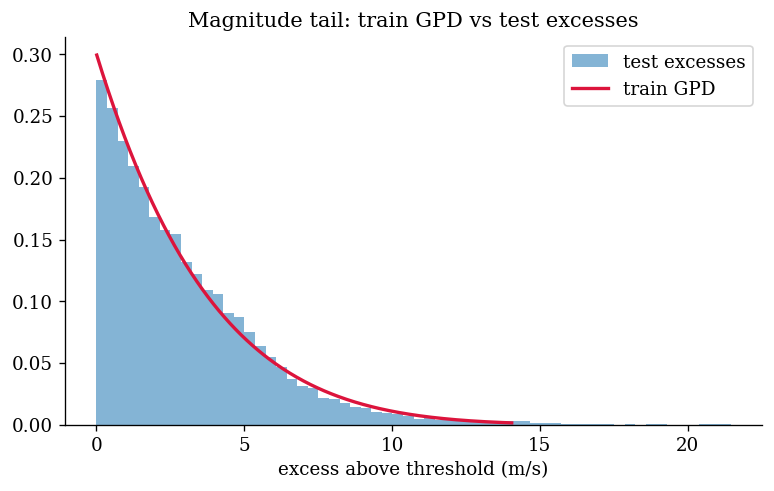

In [29]:
# GPD tail refit on TRAIN positives only + hybrid demonstration
exc_tr = np.exp(mtr)
xi_tr, _, sg_tr = genpareto.fit(exc_tr, floc=0)
print(f"Train-only GPD: xi={xi_tr:.3f}, sigma={sg_tr:.3f}")

# beyond-q90 tail: GPD conditional quantiles above the model's q90
q90_lgb = np.exp(mq_te[:, -1])
p_tail = np.array([0.95, 0.99, 0.999])
tail_q = genpareto.ppf(p_tail, xi_tr, 0, sg_tr)
print("GPD excess quantiles (m/s):",
      {f"q{int(p*1000)/10}": round(float(v), 2) for p, v in zip(p_tail, tail_q)})
print(f"LightGBM q90 median (m/s): {np.median(q90_lgb):.2f} "
      f"- hybrid rule: use GPD for probabilities beyond 0.9")

fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.hist(np.exp(mte), bins=60, density=True, alpha=0.55, label="test excesses")
xs = np.linspace(0.01, np.percentile(np.exp(mte), 99.5), 300)
ax.plot(xs, genpareto.pdf(xs, xi_tr, 0, sg_tr), "crimson", lw=2, label="train GPD")
ax.set_xlabel("excess above threshold (m/s)"); ax.legend()
ax.set_title("Magnitude tail: train GPD vs test excesses")
plt.show()

In [30]:
GATE_ON = True     # set False to skip
if GATE_ON:
    conv_tr = REG[tr_fit].astype(bool)
    def _fit_expert(mask):
        Xs, ys = Xtr[mask], ytr[mask]
        pw = float((ys == 0).sum()/max((ys == 1).sum(), 1))
        e = lgb.LGBMClassifier(objective="binary", n_estimators=800, learning_rate=0.06,
                               metric="average_precision",   # not binary_logloss
                               num_leaves=63, min_child_samples=CFG.MIN_CHILD,
                               colsample_bytree=0.8, scale_pos_weight=pw,
                               random_state=SEED, n_jobs=-1, verbosity=-1)
        e.fit(Xs, ys, eval_set=[(Xva, yva)], eval_metric="average_precision",
              callbacks=[lgb.early_stopping(60, first_metric_only=True, verbose=False)])
        return e
    exp_c = _fit_expert(conv_tr.values if hasattr(conv_tr, "values") else conv_tr)
    exp_s = _fit_expert(~(conv_tr.values if hasattr(conv_tr, "values") else conv_tr))

    # soft gate from the regime score feature
    g_te = 1/(1 + np.exp(-Xte["conv_minus_syn"].values))
    p_mix_raw = g_te*exp_c.predict_proba(Xte)[:, 1] + (1 - g_te)*exp_s.predict_proba(Xte)[:, 1]
    ap_single = average_precision_score(yte, p_te_raw)
    ap_mix = average_precision_score(yte, p_mix_raw)
    print(f"Test PR-AUC - single model: {ap_single:.4f} | regime mixture: {ap_mix:.4f}")
    print("Verdict:", "mixture helps - consider adopting" if ap_mix > ap_single + 0.002
          else "single model wins - trees already capture the regime interaction (report as ablation)")
else:
    print("Gate experiment skipped.")

Test PR-AUC - single model: 0.5845 | regime mixture: 0.5695
Verdict: single model wins - trees already capture the regime interaction (report as ablation)


In [31]:
def sedi(y, p, th):
    yhat = (p >= th).astype(int)
    tp = ((yhat==1)&(y==1)).sum(); fn = ((yhat==0)&(y==1)).sum()
    fp = ((yhat==1)&(y==0)).sum(); tn = ((yhat==0)&(y==0)).sum()
    H = tp/max(tp+fn, 1); Fr = fp/max(fp+tn, 1)
    H = min(max(H, 1e-6), 1-1e-6); Fr = min(max(Fr, 1e-6), 1-1e-6)
    num = np.log(Fr)-np.log(H)-np.log(1-Fr)+np.log(1-H)
    den = np.log(Fr)+np.log(H)+np.log(1-Fr)+np.log(1-H)
    return num/den, H, Fr

def occ_metrics(y, p, th):
    prev = y.mean()
    bs = brier_score_loss(y, p); bs_clim = brier_score_loss(y, np.full_like(p, prev))
    yhat = (p >= th).astype(int)
    tp=((yhat==1)&(y==1)).sum(); fp=((yhat==1)&(y==0)).sum(); fn=((yhat==0)&(y==1)).sum()
    prec=tp/max(tp+fp, 1); rec=tp/max(tp+fn, 1); f1=2*prec*rec/max(prec+rec, 1e-9)
    s, H, Fr = sedi(y, p, th)
    return dict(ROC_AUC=roc_auc_score(y, p), PR_AUC=average_precision_score(y, p),
                Brier=bs, BrierSkill=1-bs/bs_clim, Precision=prec, Recall=rec, F1=f1,
                SEDI=s, FreqBias=(yhat.sum()/max(y.sum(), 1)))
print("Metric functions defined (identical to CIEW).")

Metric functions defined (identical to CIEW).


In [32]:
# operating threshold: max F1 on calibrated validation probabilities
grid_thr = np.linspace(0.01, 0.9, 90)
f1v = [f1_score(yva, (p_va >= th).astype(int), zero_division=0) for th in grid_thr]
op_thr = float(grid_thr[int(np.argmax(f1v))])
print(f"Operating threshold (max-F1 on val): {op_thr:.3f}")

M_cigb = occ_metrics(yte, p_te, op_thr)
print("\nCIGB occurrence metrics (test):")
for k, v in M_cigb.items():
    print(f"  {k:12s}: {v:.4f}")

Operating threshold (max-F1 on val): 0.280

CIGB occurrence metrics (test):
  ROC_AUC     : 0.9063
  PR_AUC      : 0.5806
  Brier       : 0.0468
  BrierSkill  : 0.3415
  Precision   : 0.5411
  Recall      : 0.5085
  F1          : 0.5243
  SEDI        : 0.6997
  FreqBias    : 0.9397


In [33]:
# baselines: climatology, persistence, logistic regression
prev = yte.mean()
p_clim = np.full_like(p_te, prev)

persist_va = (gust_cells[t_idx[va_fit], c_idx[va_fit]] - THR[va_fit]).reshape(-1, 1)
persist_te = (gust_cells[t_idx[te_sel], c_idx[te_sel]] - THR[te_sel]).reshape(-1, 1)
lr_p = LogisticRegression(max_iter=200).fit(persist_va, yva)
p_persist = lr_p.predict_proba(persist_te)[:, 1]

rng = np.random.default_rng(0)
sub = rng.choice(len(tr_fit), size=min(len(tr_fit), 300_000), replace=False)
logit = make_pipeline(StandardScaler(),
                      LogisticRegression(max_iter=400, class_weight="balanced"))
logit.fit(Xtr.iloc[sub], ytr[sub])
p_logit = logit.predict_proba(Xte)[:, 1]
print("Baselines fitted.")

Baselines fitted.


In [34]:
# comparison table (adds the Transformer's rows if its results file exists)
def row(name, p):
    m = occ_metrics(yte, p, op_thr); m["Model"] = name; return m

table = pd.DataFrame([
    row("Climatology", p_clim),
    row("Persistence", p_persist),
    row("Logistic Reg", p_logit),
    row("CIGB (ours)", p_te),
]).set_index("Model")[["ROC_AUC","PR_AUC","Brier","BrierSkill","Precision","Recall","F1","SEDI"]]

ciew_csv = BASE / "model_comparison.csv"
if ciew_csv.exists():
    try:
        prev_tbl = pd.read_csv(ciew_csv, index_col=0)
        ciew_rows = prev_tbl.loc[[i for i in prev_tbl.index if "CIEW" in str(i)]]
        if len(ciew_rows):
            table = pd.concat([table, ciew_rows[table.columns.intersection(ciew_rows.columns)]])
            print("Merged CIEW row(s) from", ciew_csv.name,
                  "- NOTE: valid comparison only if CIEW ran on the same data/split.")
    except Exception as e:
        print("Could not merge CIEW table:", e)

print("="*88)
print("OCCURRENCE - MODEL COMPARISON (test period)")
print("="*88)
print(table.round(4).to_string())
table.to_csv(BASE / "cigb_model_comparison.csv")

Merged CIEW row(s) from model_comparison.csv - NOTE: valid comparison only if CIEW ran on the same data/split.
OCCURRENCE - MODEL COMPARISON (test period)
              ROC_AUC  PR_AUC   Brier  BrierSkill  Precision  Recall      F1    SEDI
Model                                                                               
Climatology    0.5000  0.0770  0.0711      0.0000     0.0000  0.0000  0.0000 -0.0000
Persistence    0.8076  0.4759  0.0539      0.2418     0.5041  0.4146  0.4550  0.6212
Logistic Reg   0.8934  0.5240  0.1217     -0.7129     0.1899  0.9083  0.3141  0.7571
CIGB (ours)    0.9063  0.5806  0.0468      0.3415     0.5411  0.5085  0.5243  0.6997
CIEW (ours)    0.8494  0.3493  0.0790     -0.1014     0.3515  0.4787  0.4054  0.5992


In [35]:
# Export test predictions with their origin times, so that confidence intervals
# can be computed later by resampling whole time blocks: rows from the same
# storm are not independent, so row-level resampling would be too optimistic.
try:
    _preds = {"Climatology": p_clim, "Persistence": p_persist,
              "Logistic Reg": p_logit, "CIGB (ours)": p_te}
    _y = yte
    _t = np.asarray(tstamp[t_idx[te_sel]]).astype("datetime64[h]").astype(np.int64)
    _path = BASE / "bootstrap_CIGB_v3.npz"
    _names = list(_preds)
    _P = np.stack([np.asarray(_preds[k], dtype=np.float32).ravel() for k in _names], 0)
    _y = np.asarray(_y).ravel().astype(np.int8)
    _t = np.asarray(_t).ravel().astype(np.int64)
    assert _P.shape[1] == _y.size == _t.size, (
        "row counts disagree -- the (origin, cell) layout is not what the export "
        "assumed: " + str((_P.shape, _y.size, _t.size)))
    np.savez_compressed(_path, P=_P, names=np.array(_names), y=_y, t=_t)
    print(f"bootstrap export -> {_path}")
    print(f"  {_P.shape[0]} series x {_y.size:,} rows | "
          f"{len(np.unique(_t // (24*14)))} fortnight blocks | base rate {_y.mean()*100:.2f}%")
except Exception as _e:
    print("!! bootstrap export failed (every result above is unaffected):", repr(_e))

bootstrap export -> /content/drive/MyDrive/MSc Dissertation/bootstrap_CIGB_v3.npz
  4 series x 2,615,600 rows | 46 fortnight blocks | base rate 7.70%


In [36]:
# inputs for the intermittent-demand baselines
_P1_GUST2D = gust_cells
_P1_THR1D  = thr_train.astype(np.float32)
_P1_LEAD   = CFG.LEAD
_P1_ROWS_VA = (t_idx[va_fit].astype(np.int64), c_idx[va_fit].astype(np.int64))
_P1_Y_VA    = yva
_P1_ROWS_TE = (t_idx[te_sel].astype(np.int64), c_idx[te_sel].astype(np.int64))
_P1_Y_TE    = yte
_P1_EXC_TE  = np.clip(FMX[te_sel] - THR[te_sel], 0.0, None)

# Intermittent-demand baselines: Croston, SBA and TSB.
# All three are causal. Smoothing constants are chosen on validation PR-AUC and
# the probabilities are isotonically calibrated on validation, as for the models.
# A per-hour rate r becomes a window probability 1 - (1 - r)^L.
try:
    from sklearn.metrics import roc_auc_score as _roc, average_precision_score as _ap
    from sklearn.metrics import brier_score_loss as _brier
    from sklearn.isotonic import IsotonicRegression as _Iso

    _ALPHAS = (0.05, 0.10, 0.20)
    _BETAS = (0.02, 0.05, 0.10)

    def _croston_states(gust2d, thr1d, keep_t, alpha, betas):
        """Causal Croston/SBA/TSB state at each t in keep_t, for every cell.

        Only the requested rows are retained, so memory tracks the evaluation
        set rather than the whole record.
        """
        T, N = gust2d.shape
        keep_t = np.asarray(keep_t)
        pos = np.full(T, -1, np.int64); pos[keep_t] = np.arange(keep_t.size)
        nb = len(betas)
        z_c = np.full(N, np.nan); p_c = np.full(N, np.nan); z_t = np.full(N, np.nan)
        q = np.zeros(N); prob = np.zeros((nb, N)); seen = np.zeros(N, bool)
        cro = np.zeros((keep_t.size, N), np.float32)
        siz = np.zeros((keep_t.size, N), np.float32)
        tsb = np.zeros((nb, keep_t.size, N), np.float32)
        tsz = np.zeros((keep_t.size, N), np.float32)
        bet = np.asarray(betas, dtype=np.float64).reshape(nb, 1)
        for t in range(T):
            g = gust2d[t]; e = g > thr1d
            q += 1.0
            if e.any():
                s = np.where(e, g - thr1d, 0.0)
                first = e & ~seen; upd = e & seen
                z_c = np.where(first, s, np.where(upd, alpha * s + (1 - alpha) * z_c, z_c))
                p_c = np.where(first, q, np.where(upd, alpha * q + (1 - alpha) * p_c, p_c))
                z_t = np.where(first, s, np.where(upd, alpha * s + (1 - alpha) * z_t, z_t))
                q = np.where(e, 0.0, q); seen = seen | e
            prob = prob + bet * (e[None, :].astype(np.float64) - prob)
            k = pos[t]
            if k >= 0:
                cro[k] = np.where(seen, 1.0 / np.maximum(p_c, 1.0), 0.0)
                siz[k] = np.where(seen, z_c, 0.0)
                tsb[:, k] = prob
                tsz[k] = np.where(seen, z_t, 0.0)
        return dict(cro=cro, siz=siz, tsb=tsb, tsz=tsz)

    def _win(rate, lead):
        r = np.clip(np.asarray(rate, dtype=np.float64), 0.0, 1.0)
        return (1.0 - (1.0 - r) ** lead).astype(np.float32)

    # bind the notebook's own arrays
    _G2, _THR1, _LEAD = _P1_GUST2D, _P1_THR1D, _P1_LEAD
    (_tv, _cv), _yva = _P1_ROWS_VA, np.asarray(_P1_Y_VA).ravel()
    (_tt, _ct), _yte = _P1_ROWS_TE, np.asarray(_P1_Y_TE).ravel()
    _keep = np.unique(np.concatenate([_tv, _tt]))
    _pk = np.full(_G2.shape[0], -1, np.int64); _pk[_keep] = np.arange(_keep.size)
    _iv, _it = _pk[_tv], _pk[_tt]
    print(f"Croston / SBA / TSB - {_G2.shape[1]} cells, {_keep.size:,} retained origins, "
          f"lead {_LEAD} h", flush=True)

    # one pass per alpha; states cached so nothing is refitted
    _ST = {}
    for _a in _ALPHAS:
        _t0 = time.time() if "time" in dir() else None
        _ST[_a] = _croston_states(_G2, _THR1, _keep, _a, _BETAS)
        print(f"  alpha={_a}: states built"
              + (f" ({time.time()-_t0:.0f}s)" if _t0 else ""), flush=True)

    _cand = {}
    for _a in _ALPHAS:
        _r = _ST[_a]["cro"][_iv, _cv]
        _cand.setdefault("Croston", []).append((_ap(_yva, _win(_r, _LEAD)), (_a, None)))
        _cand.setdefault("SBA", []).append((_ap(_yva, _win((1 - _a / 2) * _r, _LEAD)), (_a, None)))
        for _j, _b in enumerate(_BETAS):
            _cand.setdefault("TSB", []).append(
                (_ap(_yva, _win(_ST[_a]["tsb"][_j][_iv, _cv], _LEAD)), (_a, _b)))
    _best = {k: max(v, key=lambda r: r[0]) for k, v in _cand.items()}

    def _vec(nm, a, b, rows_i, rows_c):
        if nm == "Croston": return _win(_ST[a]["cro"][rows_i, rows_c], _LEAD)
        if nm == "SBA":     return _win((1 - a / 2) * _ST[a]["cro"][rows_i, rows_c], _LEAD)
        return _win(_ST[a]["tsb"][list(_BETAS).index(b)][rows_i, rows_c], _LEAD)

    def _size(nm, a, b, rows_i, rows_c):
        if nm == "TSB": return _ST[a]["tsz"][rows_i, rows_c]
        f = (1 - a / 2) if nm == "SBA" else 1.0
        return f * _ST[a]["siz"][rows_i, rows_c]

    # calibrate on validation, score on test
    _P1_PRED, _P1_SIZE, _rows_p1 = {}, {}, []
    _base = float(_yte.mean()); _bs_c = _brier(_yte, np.full(_yte.size, _base))
    for _nm, (_sv, (_a, _b)) in _best.items():
        _pv = _vec(_nm, _a, _b, _iv, _cv)
        _pt = _vec(_nm, _a, _b, _it, _ct)
        _iso = _Iso(out_of_bounds="clip").fit(_pv, _yva)
        _pc = np.clip(_iso.predict(_pt), 0, 1)
        _P1_PRED[_nm] = _pc.astype(np.float32)
        _P1_SIZE[_nm] = _size(_nm, _a, _b, _it, _ct)
        _rows_p1.append({"Model": _nm, "alpha": _a, "beta": _b,
                         "val PR": round(_sv, 4),
                         "ROC AUC": _roc(_yte, _pt), "PR AUC": _ap(_yte, _pt),
                         "Brier skill": 1 - _brier(_yte, _pc) / _bs_c})
    _rows_p1.append({"Model": "Climatology", "alpha": None, "beta": None, "val PR": None,
                     "ROC AUC": 0.5, "PR AUC": _base, "Brier skill": 0.0})
    print("\nINTERMITTENT-DEMAND BASELINES  (test, identical rows to the model above)")
    print(pd.DataFrame(_rows_p1).set_index("Model").round(4).to_string())
    print("\nCroston and SBA near climatology is the expected result: both estimate a")
    print("per-cell average RATE and barely vary in time, so they answer 'how often',")
    print("not 'when'. TSB decays through quiet spells and should separate from them.")

    # strength: expected excess vs observed, on true events
    if "_P1_EXC_TE" in dir():
        _exc = np.asarray(_P1_EXC_TE).ravel(); _pos = _yte > 0.5
        if _pos.sum() > 100:
            print("\nSTRENGTH - mean |error| in predicted excess on true events (m/s)")
            for _nm in _P1_SIZE:
                print(f"  {_nm:<9} {np.abs(_P1_SIZE[_nm][_pos] - _exc[_pos]).mean():.3f}")
            print(f"  {'climatol.':<9} "
                  f"{np.abs(_exc[_pos].mean() - _exc[_pos]).mean():.3f}")

    # append to the bootstrap export
    if "_path" in dir() and Path(str(_path)).exists():
        _z = np.load(str(_path))
        _keepn = [n for n in list(_z["names"]) if n not in _P1_PRED]
        _keepP = np.stack([_z["P"][list(_z["names"]).index(n)] for n in _keepn], 0)
        _P2 = np.concatenate([_keepP, np.stack([_P1_PRED[k] for k in _P1_PRED], 0)], 0)
        np.savez_compressed(str(_path), P=_P2.astype(np.float32),
                            names=np.array(_keepn + list(_P1_PRED)),
                            y=_z["y"], t=_z["t"])
        print(f"\nbootstrap export updated -> {_path}  ({_P2.shape[0]} series)")
    del _ST
except Exception as _e:
    import traceback; traceback.print_exc()
    print("!! intermittent baselines failed (every result above is unaffected):", repr(_e))

Croston / SBA / TSB - 520 cells, 10,069 retained origins, lead 24 h
  alpha=0.05: states built (3s)
  alpha=0.1: states built (4s)
  alpha=0.2: states built (3s)

INTERMITTENT-DEMAND BASELINES  (test, identical rows to the model above)
             alpha  beta  val PR  ROC AUC  PR AUC  Brier skill
Model                                                         
Croston       0.10   NaN  0.0884   0.5309  0.0832      -0.0025
SBA           0.10   NaN  0.0885   0.5309  0.0831      -0.0026
TSB           0.05   0.1  0.3273   0.7119  0.2980       0.1227
Climatology    NaN   NaN     NaN   0.5000  0.0770       0.0000

Croston and SBA near climatology is the expected result: both estimate a
per-cell average RATE and barely vary in time, so they answer 'how often',
not 'when'. TSB decays through quiet spells and should separate from them.

STRENGTH - mean |error| in predicted excess on true events (m/s)
  Croston   1.957
  SBA       1.960
  TSB       1.951
  climatol. 1.990

bootstrap export update

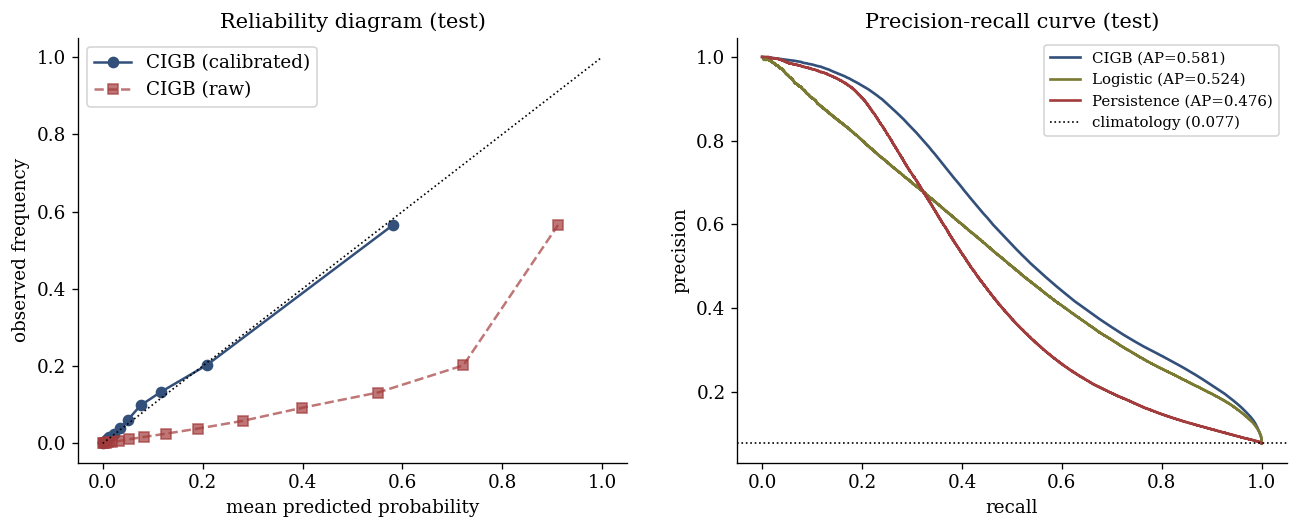

In [37]:
# reliability diagram + precision-recall curve
from sklearn.calibration import calibration_curve
from sklearn.metrics import precision_recall_curve

fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
frac_pos, mean_pred = calibration_curve(yte, p_te, n_bins=15, strategy="quantile")
ax[0].plot(mean_pred, frac_pos, "o-", color="#33507a", label="CIGB (calibrated)")
frac_r, mean_r = calibration_curve(yte, p_te_raw, n_bins=15, strategy="quantile")
ax[0].plot(mean_r, frac_r, "s--", color="#a33c3c", alpha=0.7, label="CIGB (raw)")
ax[0].plot([0, 1], [0, 1], "k:", lw=1)
ax[0].set_xlabel("mean predicted probability"); ax[0].set_ylabel("observed frequency")
ax[0].set_title("Reliability diagram (test)"); ax[0].legend()

for nm, p_, c_ in [("CIGB", p_te, "#33507a"), ("Logistic", p_logit, "#7a7a33"),
                   ("Persistence", p_persist, "#a33c3c")]:
    pr, rc, _ = precision_recall_curve(yte, p_)
    ax[1].plot(rc, pr, lw=1.6, color=c_, label=f"{nm} (AP={average_precision_score(yte, p_):.3f})")
ax[1].axhline(prev, color="k", ls=":", lw=1, label=f"climatology ({prev:.3f})")
ax[1].set_xlabel("recall"); ax[1].set_ylabel("precision")
ax[1].set_title("Precision-recall curve (test)"); ax[1].legend(fontsize=9)
plt.show()
fig.savefig(BASE / "cigb_reliability_pr.png", dpi=150, bbox_inches="tight")

In [38]:
# magnitude evaluation on test positives (vs climatological quantiles of train positives)
def pinball(y, q_pred, q):
    d = y - q_pred
    return float(np.mean(np.maximum(q*d, (q-1)*d)))

clim_q = np.quantile(mtr, QLEVELS)
rows = []
for i, q in enumerate(CFG.QUANTILES):
    rows.append({"quantile": q,
                 "CIGB": pinball(mte, mq_te[:, i], q),
                 "Climatology": pinball(mte, np.full_like(mte, clim_q[i]), q)})
pin = pd.DataFrame(rows).set_index("quantile")
pin["skill_%"] = 100*(1 - pin["CIGB"]/pin["Climatology"])
print("Pinball loss on log-excess (lower is better):")
print(pin.round(4).to_string())

mae_med = mean_absolute_error(np.exp(mte), np.exp(mq_te[:, MEDIAN_IDX]))
mae_clim = mean_absolute_error(np.exp(mte), np.full_like(mte, np.exp(clim_q[MEDIAN_IDX])))
cover = float(np.mean((mte >= mq_te[:, 0]) & (mte <= mq_te[:, -1])))
print(f"\nMedian MAE (m/s excess): CIGB {mae_med:.3f} vs climatology {mae_clim:.3f} "
      f"({100*(1-mae_med/mae_clim):.1f}% better)")
print(f"q10-q90 interval coverage: {cover*100:.1f}%  (nominal 80%)")

Pinball loss on log-excess (lower is better):
            CIGB  Climatology  skill_%
quantile                              
0.10      0.2413       0.2631   8.2929
0.25      0.3817       0.4188   8.8449
0.50      0.4217       0.4547   7.2596
0.75      0.2958       0.3137   5.6993
0.90      0.1476       0.1559   5.2697

Median MAE (m/s excess): CIGB 1.730 vs climatology 1.922 (10.0% better)
q10-q90 interval coverage: 77.7%  (nominal 80%)


In [39]:
# inputs for the severity verification
_S_TAUS  = getattr(CFG, "QUANTILES", (0.1, 0.25, 0.5, 0.75, 0.9))
_S_OBS   = np.exp(mte)
_S_TRAIN = np.exp(mtr)
_S_PRED  = {"CIGB": np.exp(mq_te)}

# Severity on true events: MAE, pinball loss and CRPS against the climatology of
# training-period excesses. The quantile grid spans 0.1-0.9, so the CRPS here is
# restricted to the central 80% (CRPS[10-90]). Skill % = 100 * (1 - model / clim).
try:
    _tau = np.asarray(_S_TAUS, dtype=np.float64)
    _obs = np.asarray(_S_OBS, dtype=np.float64).ravel()
    _tr = np.asarray(_S_TRAIN, dtype=np.float64).ravel()
    _tr = _tr[np.isfinite(_tr)]
    assert _obs.size > 50, f"only {_obs.size} scored events"

    def _pinball_vec(obs, q, tau):
        """Mean pinball loss per quantile level. obs (n,), q (n,K), tau (K,)."""
        d = obs[:, None] - q
        return np.mean(np.maximum(tau[None, :] * d, (tau[None, :] - 1.0) * d), axis=0)

    def _crps_from_pinball(pb, tau):
        """CRPS = 2 * integral of pinball over tau, trapezoid on the given grid."""
        return 2.0 * np.trapezoid(pb, tau) if hasattr(np, "trapezoid") \
            else 2.0 * np.trapz(pb, tau)

    # climatological reference: the same quantiles for every event
    _cq = np.quantile(_tr, _tau)
    _clim = np.repeat(_cq[None, :], _obs.size, axis=0)
    _pb_c = _pinball_vec(_obs, _clim, _tau)
    _crps_c = _crps_from_pinball(_pb_c, _tau)
    _mid = int(np.argmin(np.abs(_tau - 0.5)))
    _mae_c = float(np.abs(_obs - _cq[_mid]).mean())

    print("=" * 78)
    print(f"STRENGTH ON TRUE EVENTS  (n={_obs.size:,} exceedances, excess in m/s)")
    print(f"reference: climatology of {_tr.size:,} training-period excesses, "
          f"median {_cq[_mid]:.2f} m/s")
    print("=" * 78)

    _srows, _prows = [], []
    for _nm, _qp in _S_PRED.items():
        _q = np.asarray(_qp, dtype=np.float64)
        assert _q.shape == (_obs.size, _tau.size), f"{_nm}: {_q.shape} vs {(_obs.size, _tau.size)}"
        _q = np.sort(_q, axis=1)                      # enforce monotone quantiles
        _pb = _pinball_vec(_obs, _q, _tau)
        _crps = _crps_from_pinball(_pb, _tau)
        _mae = float(np.abs(_obs - _q[:, _mid]).mean())
        _cov = float(np.mean((_obs >= _q[:, 0]) & (_obs <= _q[:, -1])))
        _srows.append({"Model": _nm,
                       "MAE m/s": _mae, "MAE skill %": 100 * (1 - _mae / _mae_c),
                       "CRPS[10-90]": _crps, "CRPS skill %": 100 * (1 - _crps / _crps_c),
                       f"cover [{_tau[0]:.2f},{_tau[-1]:.2f}]": _cov,
                       "nominal": _tau[-1] - _tau[0]})
        for _i, _t in enumerate(_tau):
            _prows.append({"quantile": _t, "Model": _nm, "pinball": _pb[_i],
                           "climatology": _pb_c[_i],
                           "skill_%": 100 * (1 - _pb[_i] / _pb_c[_i])})

    _srows.append({"Model": "Climatology", "MAE m/s": _mae_c, "MAE skill %": 0.0,
                   "CRPS[10-90]": _crps_c, "CRPS skill %": 0.0,
                   f"cover [{_tau[0]:.2f},{_tau[-1]:.2f}]": np.nan,
                   "nominal": _tau[-1] - _tau[0]})
    _S_TABLE = pd.DataFrame(_srows).set_index("Model")
    print(_S_TABLE.round(4).to_string())

    print("\nPinball loss by quantile (m/s excess, lower is better)")
    _P_TABLE = pd.DataFrame(_prows).pivot(index="quantile", columns="Model",
                                          values=["pinball", "skill_%"])
    print(_P_TABLE.round(4).to_string())

    if "BASE" in dir():
        _S_TABLE.to_csv(Path(str(BASE)) / "strength_verification.csv")
        print(f"\nwritten -> {Path(str(BASE)) / 'strength_verification.csv'}")
    elif "CFG" in dir() and hasattr(CFG, "CACHE"):
        _S_TABLE.to_csv(CFG.CACHE / "strength_verification.csv")
        print(f"\nwritten -> {CFG.CACHE / 'strength_verification.csv'}")
except Exception as _e:
    import traceback; traceback.print_exc()
    print("!! strength verification failed (every result above is unaffected):", repr(_e))

STRENGTH ON TRUE EVENTS  (n=201,360 exceedances, excess in m/s)
reference: climatology of 506,090 training-period excesses, median 2.24 m/s
             MAE m/s  MAE skill %  CRPS[10-90]  CRPS skill %  cover [0.10,0.90]  nominal
Model                                                                                   
CIGB          1.7303       9.9824       1.1026        9.5322              0.777      0.8
Climatology   1.9222       0.0000       1.2187        0.0000                NaN      0.8

Pinball loss by quantile (m/s excess, lower is better)
         pinball skill_%
Model       CIGB    CIGB
quantile                
0.10      0.2597  6.3043
0.25      0.5632  9.3075
0.50      0.8651  9.9824
0.75      0.8186  9.4472
0.90      0.5221  9.5837

written -> /content/drive/MyDrive/MSc Dissertation/strength_verification.csv


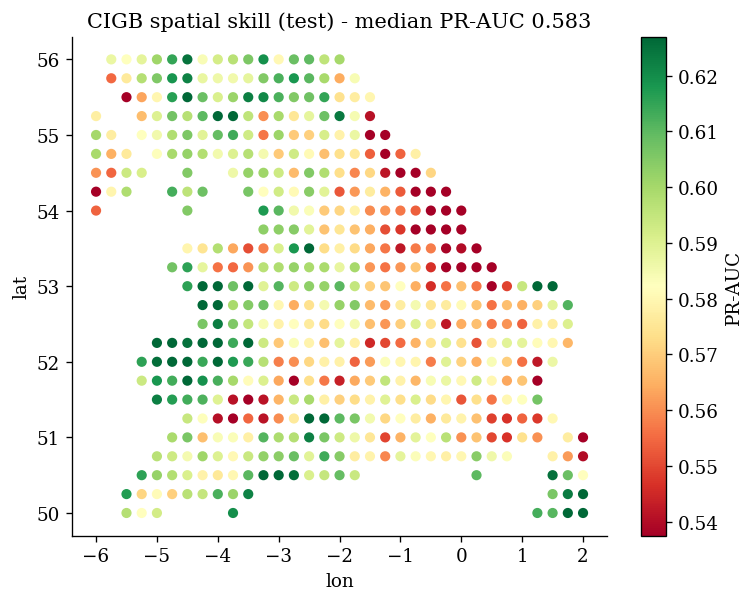

In [40]:
# spatial skill map: PR-AUC per cell on test
cell_ap = np.full(N_CELLS, np.nan)
te_c = c_idx[te_sel]
for k in range(N_CELLS):
    m_ = te_c == k
    if m_.sum() > 50 and yte[m_].sum() >= 10:
        cell_ap[k] = average_precision_score(yte[m_], p_te[m_])
fig, ax = plt.subplots(figsize=(7.2, 5.4))
sc = ax.scatter(cell_lon, cell_lat, c=cell_ap, s=26, cmap="RdYlGn",
                vmin=np.nanpercentile(cell_ap, 5), vmax=np.nanpercentile(cell_ap, 95))
plt.colorbar(sc, ax=ax, label="PR-AUC")
ax.set_xlabel("lon"); ax.set_ylabel("lat")
ax.set_title(f"CIGB spatial skill (test) - median PR-AUC {np.nanmedian(cell_ap):.3f}")
plt.show()
fig.savefig(BASE / "cigb_spatial_skill.png", dpi=150, bbox_inches="tight")

Worst test-window gust: 44.6 m/s at cell 471 (lat 55.50, lon -5.25), origin 2025-01-23 14:00:00


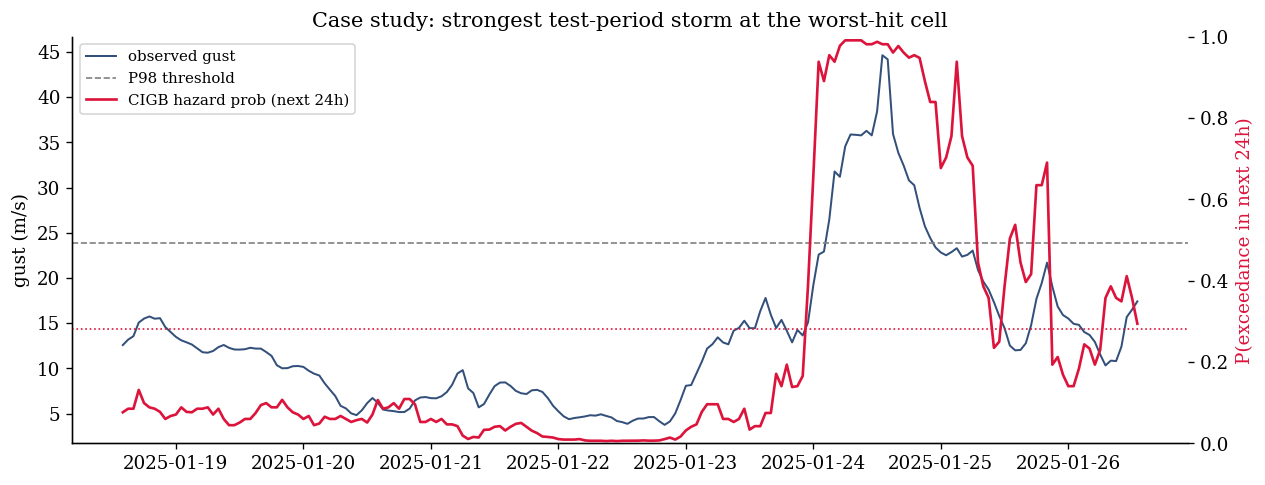

In [41]:
# case study: worst observed test gust - did the model warn ahead?
te_t = t_idx[te_sel]
i_worst = int(np.argmax(FMX[te_sel]))
k_star, t_star = int(te_c[i_worst]), int(te_t[i_worst])
print(f"Worst test-window gust: {FMX[te_sel][i_worst]:.1f} m/s at cell {k_star} "
      f"(lat {cell_lat[k_star]:.2f}, lon {cell_lon[k_star]:.2f}), origin {times[t_star]}")

w0, w1 = max(t_star - 120, CFG.HIST), min(t_star + 72, T - CFG.LEAD - 1)
ts_win = np.arange(w0, w1)
sel_win = np.stack([ts_win, np.full_like(ts_win, k_star)], axis=1)
Xw = pd.DataFrame({**{n: a[ts_win, k_star] for n, a in FEAT.items()},
                   **{n: v[ts_win] for n, v in TFEAT.items()},
                   **{n: np.full(len(ts_win), v[k_star], np.float32) for n, v in SFEAT.items()}
                   }).astype(np.float32)[Xtr.columns]
pw = iso.predict(clf.predict_proba(Xw)[:, 1])

fig, ax1 = plt.subplots(figsize=(12, 4.4))
ax1.plot(times[ts_win], gust_cells[ts_win, k_star], color="#33507a", lw=1.2, label="observed gust")
ax1.axhline(thr_train[k_star], color="gray", ls="--", lw=1, label="P98 threshold")
ax1.set_ylabel("gust (m/s)")
ax2 = ax1.twinx()
ax2.plot(times[ts_win], pw, color="crimson", lw=1.6, label="CIGB hazard prob (next 24h)")
ax2.axhline(op_thr, color="crimson", ls=":", lw=1)
ax2.set_ylabel("P(exceedance in next 24h)", color="crimson"); ax2.set_ylim(0, 1)
lines = ax1.get_legend_handles_labels(); lines2 = ax2.get_legend_handles_labels()
ax1.legend(lines[0]+lines2[0], lines[1]+lines2[1], loc="upper left", fontsize=9)
ax1.set_title("Case study: strongest test-period storm at the worst-hit cell")
plt.show()
fig.savefig(BASE / "cigb_case_study.png", dpi=150, bbox_inches="tight")

In [42]:
SHAP_OK = True
try:
    import shap
    rng = np.random.default_rng(SEED)
    sh_idx = rng.choice(len(Xte), size=min(20_000, len(Xte)), replace=False)
    X_sh = Xte.iloc[sh_idx]
    expl = shap.TreeExplainer(clf)
    sv = expl.shap_values(X_sh)
    if isinstance(sv, list):           # older shap returns [neg, pos]
        sv = sv[1]
    print("SHAP values computed:", sv.shape)
except Exception as e:
    SHAP_OK = False
    print("SHAP unavailable - skipping interpretability cells:", e)

SHAP values computed: (20000, 69)


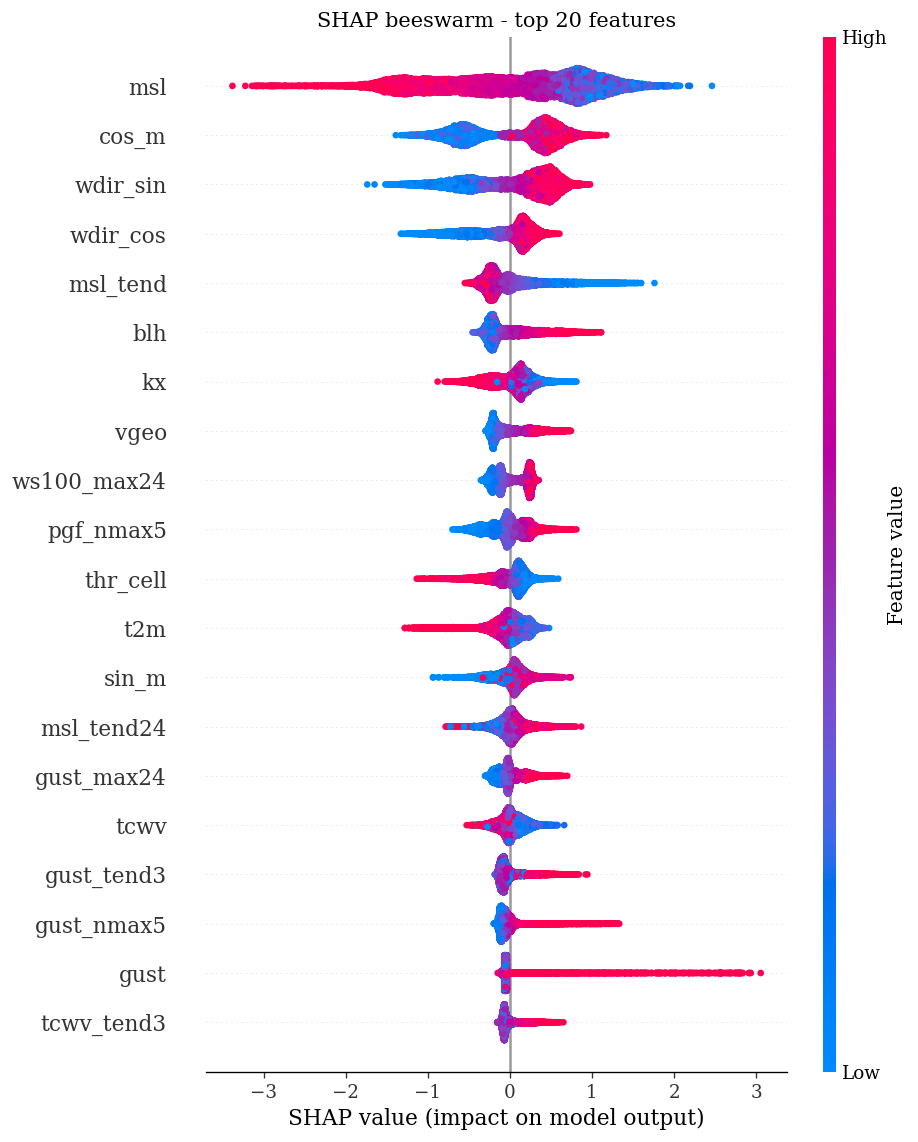

In [43]:
if SHAP_OK:
    shap.summary_plot(sv, X_sh, max_display=20, show=False)
    plt.title("SHAP beeswarm - top 20 features")
    plt.gcf().savefig(BASE / "cigb_shap_beeswarm.png", dpi=150, bbox_inches="tight")
    plt.show()

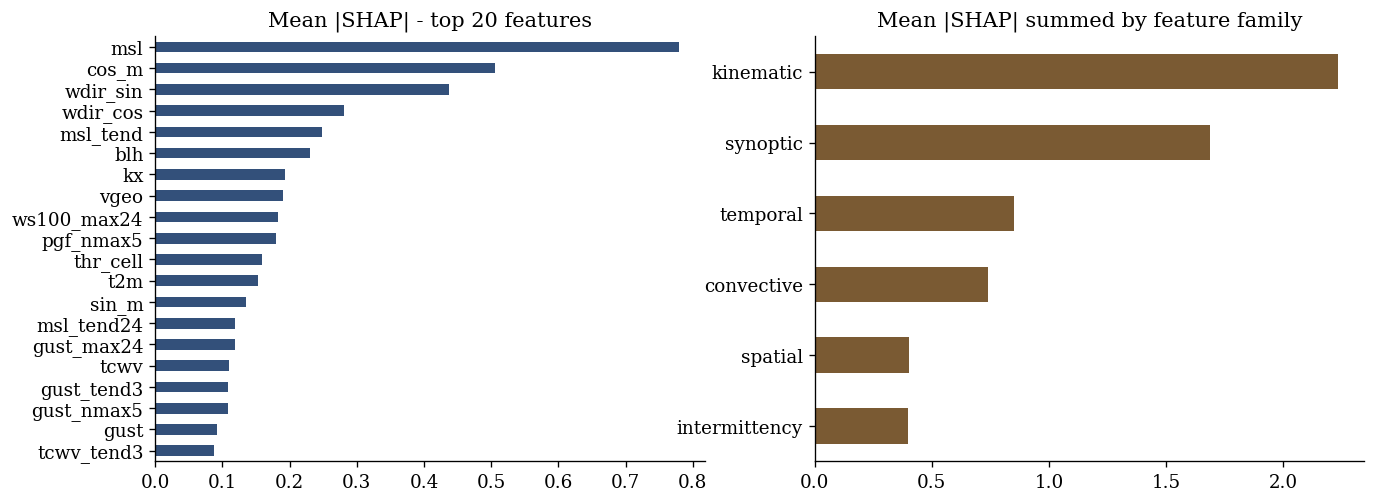


Family shares (%):
kinematic        35.4
synoptic         26.7
temporal         13.5
convective       11.7
spatial           6.4
intermittency     6.3


In [44]:
if SHAP_OK:
    mean_abs = pd.Series(np.abs(sv).mean(axis=0), index=X_sh.columns)
    fam_imp = pd.Series({fam: mean_abs.reindex(cols).dropna().sum()
                         for fam, cols in FAMILIES.items()}).sort_values()
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
    mean_abs.sort_values().tail(20).plot.barh(ax=ax[0], color="#33507a")
    ax[0].set_title("Mean |SHAP| - top 20 features")
    fam_imp.plot.barh(ax=ax[1], color="#7a5a33")
    ax[1].set_title("Mean |SHAP| summed by feature family")
    plt.show()
    print("\nFamily shares (%):")
    print((100*fam_imp/fam_imp.sum()).round(1).sort_values(ascending=False).to_string())

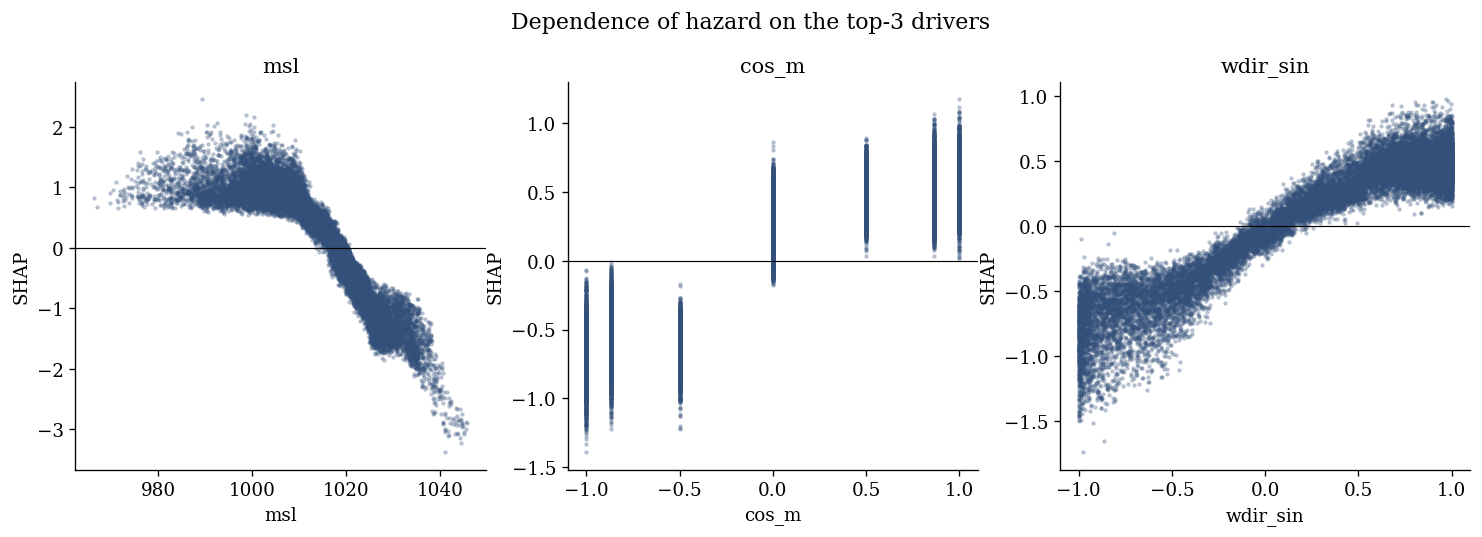

In [45]:
if SHAP_OK:
    top3 = pd.Series(np.abs(sv).mean(axis=0), index=X_sh.columns).nlargest(3).index
    fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
    for a, f_ in zip(ax, top3):
        j = list(X_sh.columns).index(f_)
        a.scatter(X_sh[f_], sv[:, j], s=3, alpha=0.25, c="#33507a")
        a.axhline(0, color="k", lw=0.7)
        a.set_xlabel(f_); a.set_ylabel("SHAP")
        a.set_title(f_)
    plt.suptitle("Dependence of hazard on the top-3 drivers", y=1.02)
    plt.show()

In [46]:
ABL_CAP = min(len(tr_fit), 2_000_000)
rng = np.random.default_rng(SEED)
abl_tr = np.sort(rng.choice(len(tr_fit), ABL_CAP, replace=False))

def quick_fit(cols):
    pw = float((ytr[abl_tr] == 0).sum()/max((ytr[abl_tr] == 1).sum(), 1))
    m = lgb.LGBMClassifier(objective="binary", n_estimators=600, learning_rate=0.08,
                           metric="average_precision",   # not binary_logloss
                           num_leaves=63, min_child_samples=CFG.MIN_CHILD,
                           colsample_bytree=0.8, scale_pos_weight=pw,
                           random_state=SEED, n_jobs=-1, verbosity=-1)
    m.fit(Xtr.iloc[abl_tr][cols], ytr[abl_tr],
          eval_set=[(Xva[cols], yva)], eval_metric="average_precision",
          callbacks=[lgb.early_stopping(60, first_metric_only=True, verbose=False)])
    p = m.predict_proba(Xte[cols])[:, 1]
    return average_precision_score(yte, p), roc_auc_score(yte, p), int(m.best_iteration_ or 600)

ALL = list(Xtr.columns)
meteo = (FAMILIES["convective"] + FAMILIES["synoptic"]
         + FAMILIES["kinematic"] + FAMILIES["spatial"])
runs = {"full (all families)": ALL}
for fam in FAMILIES:
    runs[f"minus {fam}"] = [c for c in ALL if c not in FAMILIES[fam]]
# dynamics specific runs
DYN = [c for c in ["adv_gust", "pgf", "lap", "vgeo", "msl_tend", "msl_tend3", "msl_tend24",
                   "pgf_max24", "pgf_max48", "pgf_mean24", "vgeo_max24", "vgeo_max48",
                   "vgeo_mean24", "pgf_nmax5"] if c in ALL]
if "adv_gust" in ALL:
    runs["minus advection only"] = [c for c in ALL if c != "adv_gust"]
runs["minus all dynamics"] = [c for c in ALL if c not in DYN]
runs["dynamics only"] = DYN + FAMILIES["temporal"]

runs["intermittency only"] = FAMILIES["intermittency"] + FAMILIES["temporal"]
runs["meteorology only"]   = [c for c in meteo + FAMILIES["temporal"] if c in ALL]

rows = []
for nm, cols in runs.items():
    t0 = time.time()
    ap, auc, bi = quick_fit(cols)
    rows.append({"Run": nm, "n_features": len(cols), "PR_AUC": ap, "ROC_AUC": auc,
                 "best_iter": bi})
    print(f"  {nm:28s} PR-AUC {ap:.4f}  best_iter {bi:4d}  ({time.time()-t0:.0f}s)")

abl = pd.DataFrame(rows).set_index("Run")
abl["dPR_AUC_vs_full"] = abl["PR_AUC"] - abl.loc["full (all families)", "PR_AUC"]
print("\n" + "="*72)
print(abl.round(4).to_string())
abl.to_csv(BASE / "cigb_ablation.csv")

  full (all families)          PR-AUC 0.5816  best_iter  211  (90s)
  minus intermittency          PR-AUC 0.5792  best_iter  195  (77s)
  minus convective             PR-AUC 0.5740  best_iter  230  (84s)
  minus synoptic               PR-AUC 0.5614  best_iter  248  (88s)
  minus kinematic              PR-AUC 0.5589  best_iter  175  (61s)
  minus spatial                PR-AUC 0.5763  best_iter  309  (124s)
  minus temporal               PR-AUC 0.5824  best_iter  274  (102s)
  minus advection only         PR-AUC 0.5793  best_iter  212  (88s)
  minus all dynamics           PR-AUC 0.5680  best_iter  250  (84s)
  dynamics only                PR-AUC 0.4901  best_iter  163  (44s)
  intermittency only           PR-AUC 0.3482  best_iter    7  (11s)
  meteorology only             PR-AUC 0.5788  best_iter  231  (88s)

                      n_features  PR_AUC  ROC_AUC  best_iter  dPR_AUC_vs_full
Run                                                                          
full (all families)      

In [47]:
summary = {
    "model": "CIGB - Convection-Informed Gradient-Boosted Hazard Model",
    "data": "ERA5",
    "period": [str(times[0]), str(times[-1])],
    "n_cells": int(N_CELLS), "n_features": int(len(FEATURE_COLS)),
    "task": f"P(gust > train-P{int(CFG.POT_Q*100)} in next {CFG.LEAD}h) + excess quantiles",
    "samples": {"train": int(len(tr_sel)), "val": int(len(va_sel)), "test": int(len(te_sel))},
    "best_iteration": int(clf.best_iteration_ or CFG.N_EST),
    "operating_threshold": op_thr,
    "occurrence_test": {k: round(float(v), 4) for k, v in M_cigb.items()},
    "magnitude_test": {
        "median_MAE_ms": round(float(mae_med), 3),
        "q10_q90_coverage": round(float(cover), 3),
        "pinball_skill_vs_clim_%": {str(q): round(float(s), 1)
                                    for q, s in zip(pin.index, pin["skill_%"])},
    },
    "gpd_train": {"xi": round(float(xi_tr), 3), "sigma": round(float(sg_tr), 3)},
}
with open(BASE / "cigb_summary.json", "w") as f:
    json.dump(summary, f, indent=2)
print(json.dumps(summary, indent=2))
print("\nArtifacts written to", BASE)
for f_ in ["cigb_summary.json", "cigb_model_comparison.csv", "cigb_ablation.csv",
           "cigb_reliability_pr.png", "cigb_spatial_skill.png", "cigb_case_study.png",
           "cigb_shap_beeswarm.png"]:
    print("  -", f_)

{
  "model": "CIGB - Convection-Informed Gradient-Boosted Hazard Model",
  "data": "ERA5",
  "period": [
    "2015-01-01 00:00:00",
    "2026-06-30 19:00:00"
  ],
  "n_cells": 520,
  "n_features": 69,
  "task": "P(gust > train-P98 in next 24h) + excess quantiles",
  "samples": {
    "train": 12218960,
    "val": 2620280,
    "test": 2615600
  },
  "best_iteration": 1983,
  "operating_threshold": 0.28,
  "occurrence_test": {
    "ROC_AUC": 0.9063,
    "PR_AUC": 0.5806,
    "Brier": 0.0468,
    "BrierSkill": 0.3415,
    "Precision": 0.5411,
    "Recall": 0.5085,
    "F1": 0.5243,
    "SEDI": 0.6997,
    "FreqBias": 0.9397
  },
  "magnitude_test": {
    "median_MAE_ms": 1.73,
    "q10_q90_coverage": 0.777,
    "pinball_skill_vs_clim_%": {
      "0.1": 8.3,
      "0.25": 8.8,
      "0.5": 7.3,
      "0.75": 5.7,
      "0.9": 5.3
    }
  },
  "gpd_train": {
    "xi": -0.132,
    "sigma": 3.331
  }
}

Artifacts written to /content/drive/MyDrive/MSc Dissertation
  - cigb_summary.json
  - cigb